# Лабораторная работа №7 (В26)
## Введение
**Название:** деревья решений и ансамбли на их основе

**Цели:** 1. освоить принципы построения и настройки дерева решений с помощью sklearn.tree.DecisionTreeClassifie;
2. познакомиться с базовыми ансамблевыми методами: бэггинг (Bagging) и
бустинг (Boosting);
3. сравнить эффективность одиночного дерева и ансамблей на практическом примере.

**Описание показателей:**
- age - возраст
- job - тип работы
- marital - семейное положение
- education - образование
- default - просрочен ли кредит
- balance - среднегодовой баланс в евро
- housing - есть ли ссуда на жильё
- loan - есть ли ссуда на личные нужды
- contact - тип связи с контактом
- day - последний день контакта в месяце
- month - месяц последнего контакта в году
- duration - продолжительность последнего контакта в секундах
- campaign - количество контактов, осуществлённых в ходе этой компании и для данного клиента
- pdays - количество дней с момента последнего контакта с клиентом в рамках предыдущей компании
- previous - количество контактов, осуществлённых до этой компании и для данного клиента
- poutcome - результат предыдущей маркетинговой компании

## 1. Подготовительный этап
### 1.1 Импорт необходимых библиотек

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


### 1.2 Читаем датасет, делим его и внимательно сомтрим

In [8]:
# используем указание разделителя delimiter
df = pd.read_csv('bank.csv', delimiter = ';')
# разделяем данные на признаки и целевую переменную
y = df['y']
X = df.drop('y', axis=1)

# посмотрим на данные
print("Размерность признаков:", X.shape)
print("Названия признаков:", X.columns.tolist())
print("Размерность целевой переменной:", y.shape)
print("Уникальные значения целевой переменной:", y.unique())
print("Первые 5 строк признаков:")
print(X.head())

Размерность признаков: (4521, 16)
Названия признаков: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']
Размерность целевой переменной: (4521,)
Уникальные значения целевой переменной: ['no' 'yes']
Первые 5 строк признаков:
   age          job  marital  education default  balance housing loan  \
0   30   unemployed  married    primary      no     1787      no   no   
1   33     services  married  secondary      no     4789     yes  yes   
2   35   management   single   tertiary      no     1350     yes   no   
3   30   management  married   tertiary      no     1476     yes  yes   
4   59  blue-collar  married  secondary      no        0     yes   no   

    contact  day month  duration  campaign  pdays  previous poutcome  
0  cellular   19   oct        79         1     -1         0  unknown  
1  cellular   11   may       220         1    339         4  failure  
2  cellular

### 1.3 Разделение данных на обучающую и тестовую выборки

In [ ]:
# Но для начала нам необходимо закодировать категориальные признаки, 
# поскольку иначе не работает построение дерева решений (выдаёт ошибку)
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)
print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (3616, 42)
Размер тестовой выборки: (905, 42)


## 2. Построение и оценка базового дерева решений
### 2.1 Создадим и обучим модель дерева решений без настройки гиперпараметров

In [13]:
base_dt = DecisionTreeClassifier(random_state=42)
base_dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

Сделаем прогнозы и оценим точность

In [26]:
y_pred_base = base_dt.predict(X_test)
accuracy_base = accuracy_score(y_test, y_pred_base)
print(f"Точность базового дерева: {100*accuracy_base:.2f}%")

Точность базового дерева: 84.86%


Визуализируем дерево (получится большим, тк не ограничено)
Используем max_depth для читаемости

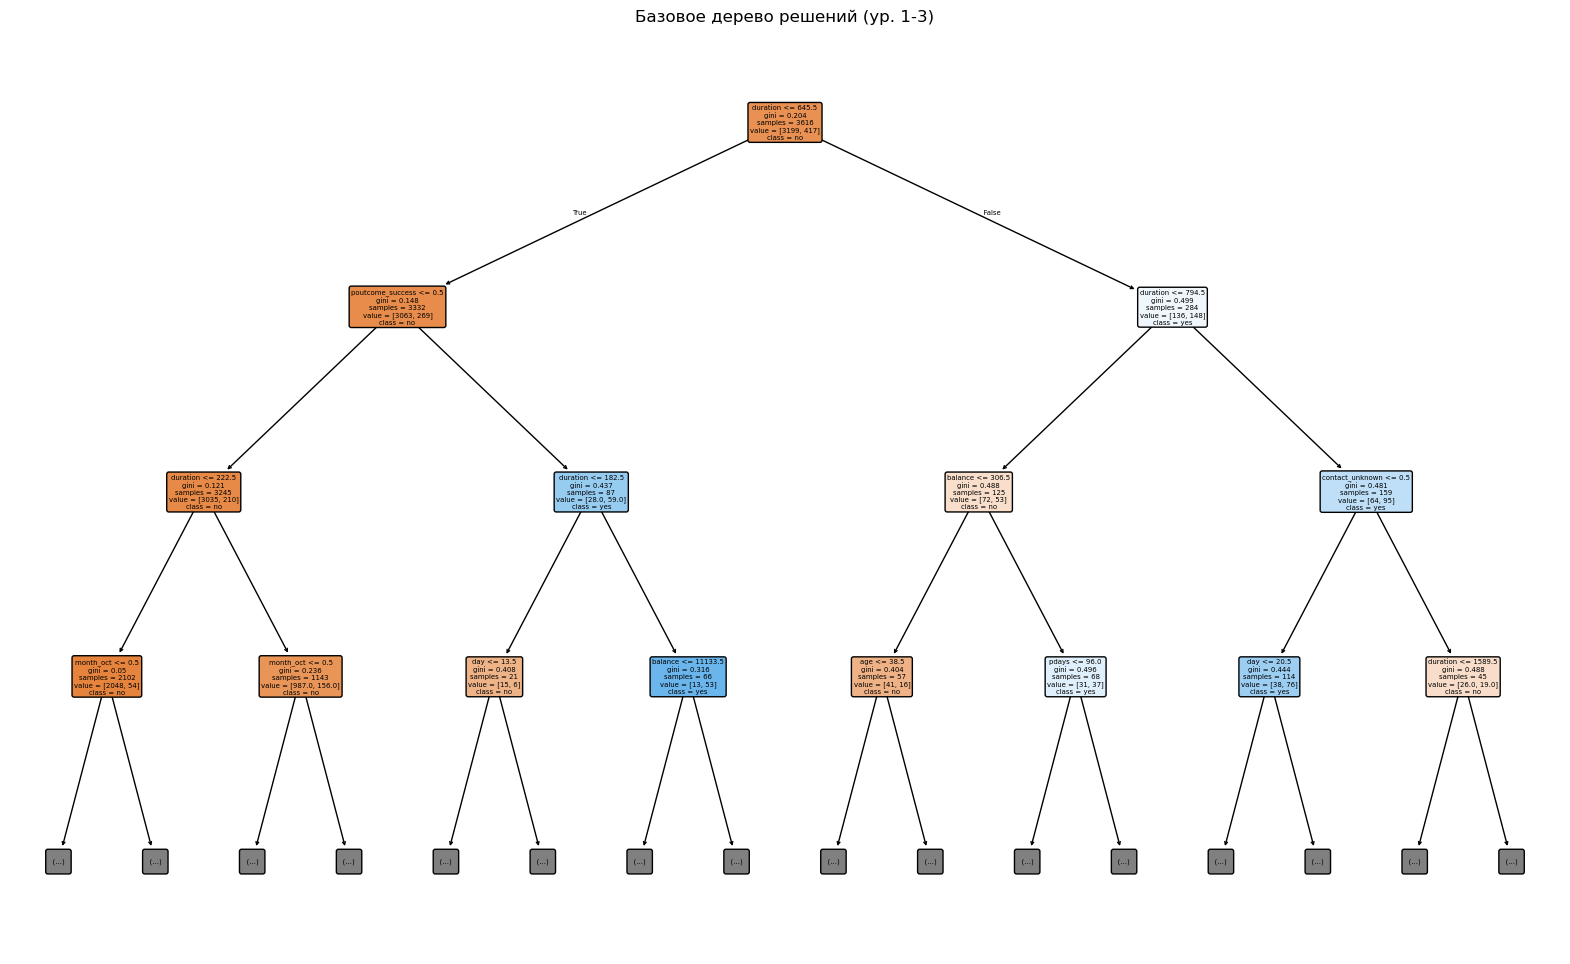

In [27]:
plt.figure(figsize=(20, 12))
plot_tree(base_dt, filled=True, feature_names=X.columns,
           class_names=sorted(y.unique()), rounded=True, max_depth=3)
plt.title("Базовое дерево решений (ур. 1-3)")
plt.show()

### 2.2 Настроим гиперпараметры, чтобы избежать переобучения
Ограничим глубину дерева

In [29]:
tuned_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
tuned_dt.fit(X_train, y_train)
y_pred_tuned = tuned_dt.predict(X_test)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Точность тюннингованного дерева с глубиной 3: {100*accuracy_tuned:.2f}%")

Точность тюннингованного дерева с глубиной 3: 88.84%


Устроим кросс-валидацию обоих деревьев, а после визуализируем тюннингованное

In [34]:
cv_scores_base = cross_val_score(base_dt, X, y, cv=5)
cv_scores_tuned = cross_val_score(tuned_dt, X, y, cv=5)
print(f"Кросс-валидация base: {np.mean(cv_scores_base) * 100:.2f}% +/- {np.std(cv_scores_base) * 200:.2f}%")
print(f"Кросс-валидация tuned: {np.mean(cv_scores_tuned) * 100:.2f}% +/- {np.std(cv_scores_tuned) * 200:.2f}%")

Кросс-валидация base: 87.15% +/- 1.19%
Кросс-валидация tuned: 89.89% +/- 0.60%


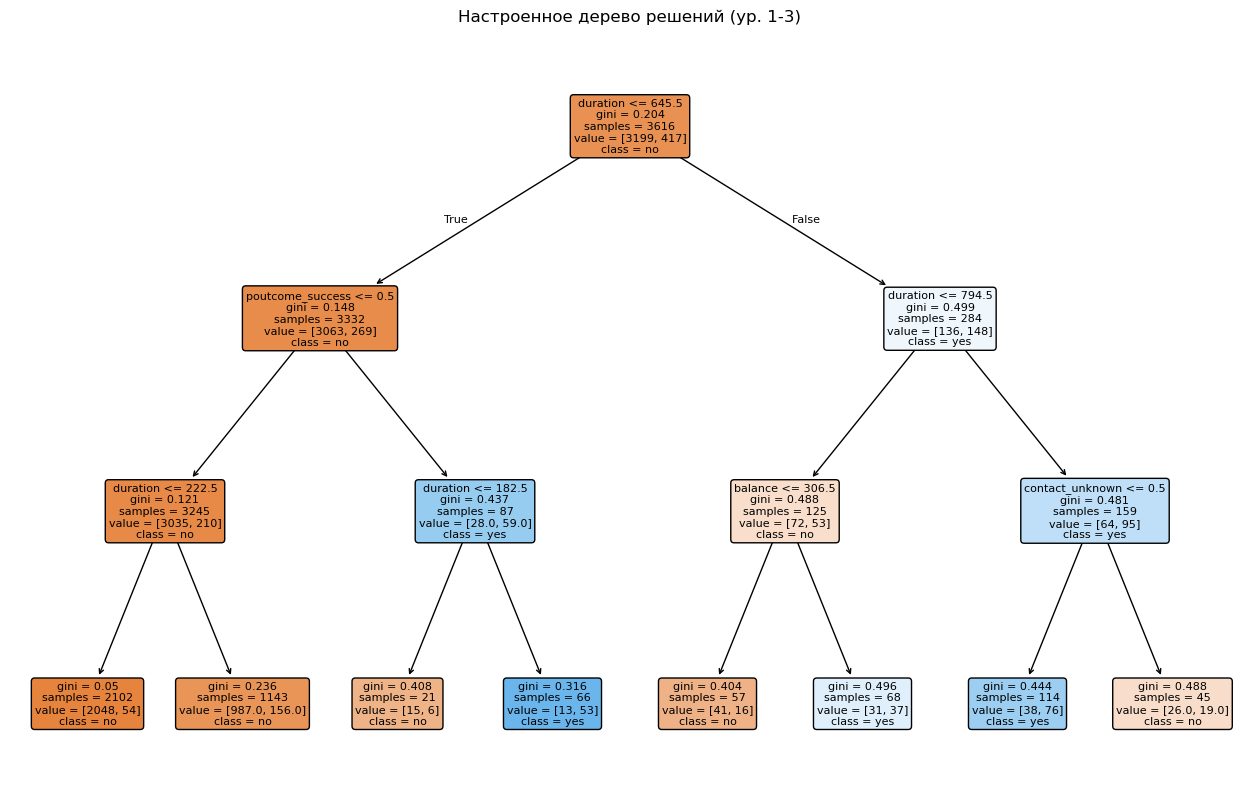

In [35]:
plt.figure(figsize=(16,10))
plot_tree(tuned_dt, filled=True, feature_names=X.columns,
           class_names=sorted(y.unique()), rounded=True)
plt.title("Настроенное дерево решений (ур. 1-3)")
plt.show()

### 2.3 Узнаем важность признаков
Выведем топ-5

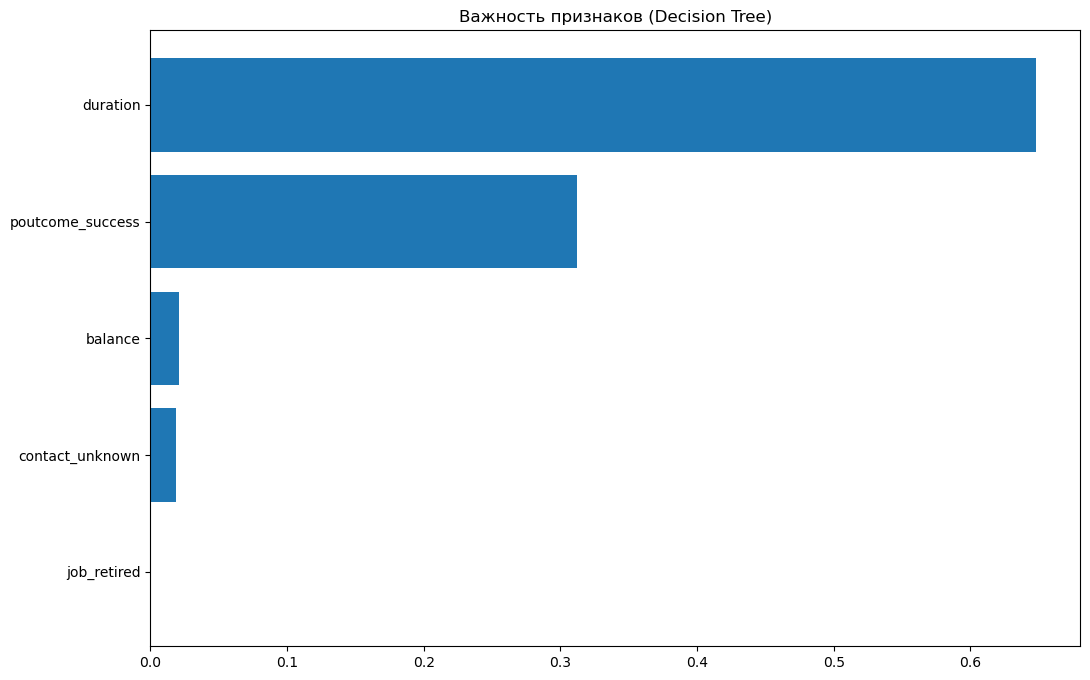

In [40]:
importances = tuned_dt.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 8))
plt.title("Важность признаков (Decision Tree)")
plt.barh(range(5), importances[indices][:5])
plt.yticks(range(5), [X.columns[i] for i in indices[:5]])
plt.gca().invert_yaxis()
plt.show()

## 3. Ансамбли
### 3.1 Случайный лес (bagging)
Создадим и обучим случайный лес, сделаем прогноз и оценим его, сравним важность признаков с одиночным деревом

In [41]:
rf = RandomForestClassifier(n_estimators=100, random_state=42) #100 деревьев
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [42]:
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Точность случайного леса: {accuracy_rf*100:.2f}%")

Точность случайного леса: 88.73%


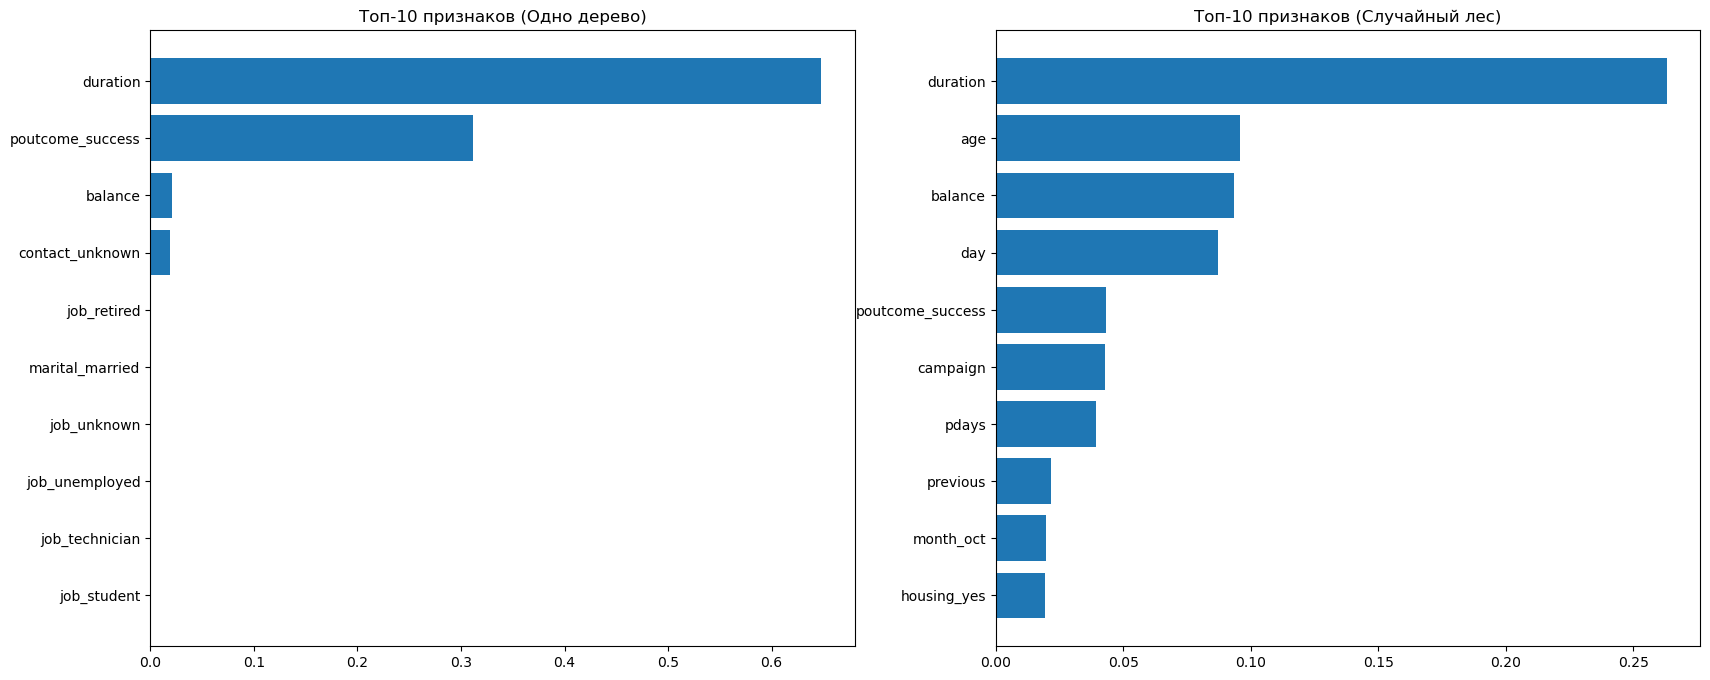

In [43]:
rf_importances = rf.feature_importances_
indices_rf = np.argsort(rf_importances)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
ax1.barh(range(10), importances[indices][:10])
ax1.set_title("Топ-10 признаков (Одно дерево)")
ax1.set_yticks(range(10))
ax1.set_yticklabels([X.columns[i] for i in indices[:10]])
ax1.invert_yaxis()

ax2.barh(range(10), rf_importances[indices_rf][:10])
ax2.set_title("Топ-10 признаков (Случайный лес)")
ax2.set_yticks(range(10))
ax2.set_yticklabels([X.columns[i] for i in indices_rf[:10]])
ax2.invert_yaxis()
plt.show()

### 3.2 Грандиентный бустинг (boosting)
Создадим и обучим ГБ, создадим прогноз и оценим его точность 

In [44]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Точность GB: {accuracy_gb*100:.2f}%")

Точность GB: 89.17%


## 4. Сравним все модели в сводной таблице результатов

In [47]:
models = {
    'Base Decision Tree': base_dt,
    'Tuned Decision Tree': tuned_dt,
    'Random Forest': rf,
    'Gradient Boosting': gb
}

results = {}
for name, model in models.items():
    # Обучаем на полном тренировочном наборе (если еще не обучен)
    if name not in ['Base Decision Tree', 'Tuned Decision Tree']:
        model.fit(X_train, y_train)
    # Считаем accuracy на тренировочном и тестовом наборах
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    results[name] = {'Train Accuracy': train_acc*100, 'Test Accuracy': test_acc*100}

                     Train Accuracy  Test Accuracy
Base Decision Tree       100.000000      84.861878
Tuned Decision Tree       90.790929      88.839779
Random Forest            100.000000      88.729282
Gradient Boosting         93.860619      89.171271


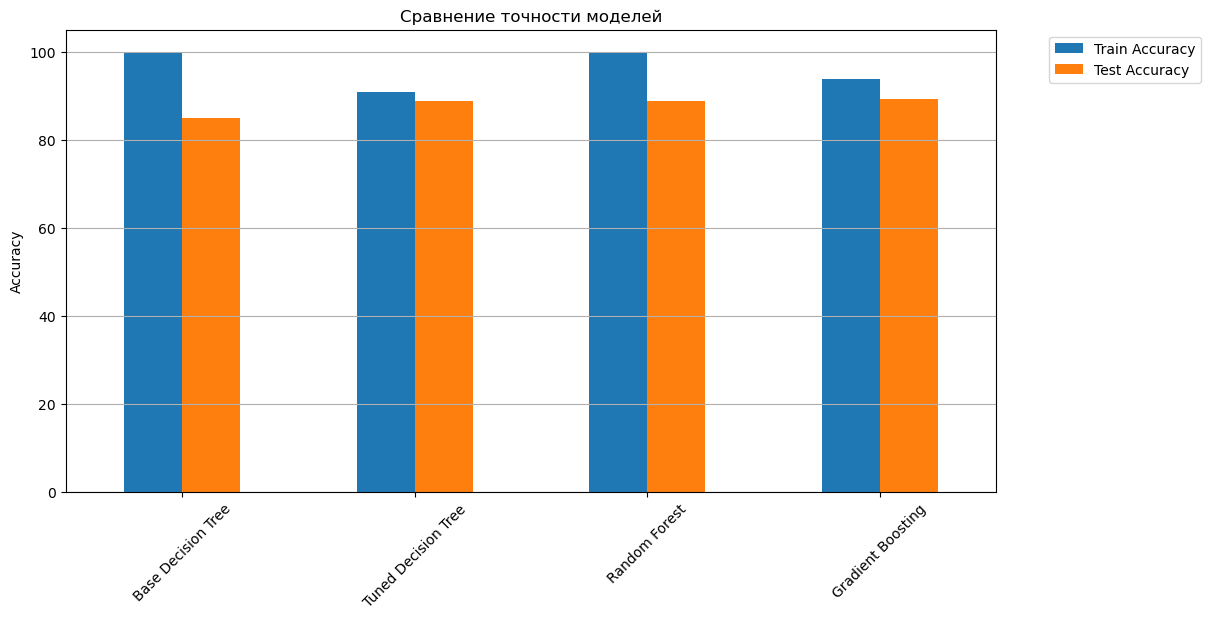

In [48]:
results_df = pd.DataFrame(results).T
print(results_df)

results_df[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(12, 6))
plt.title('Сравнение точности моделей')
plt.ylabel ('Accuracy')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis="y")
plt.show()

Как можно заметить, для тестовой выборки хуже всего подходит не настроенное дерево. Остальные варианты обеспечивают результат в 89%. При это рандомный лес показал 100% на обучающей выборке, а градиентный бустинг 93%, что делает их более привлекательными, чем тюннингованное дерево решений.
Лабораторная работа 7 выполнена

# 5. Баловство и тюнниг методов

In [89]:
# выше мы достигли точности в 89.17% (n=100, random=42). Попробуем её поднять
# n=150 89.39%, random=90 лучший результат при лёгком тюннинге бустинга
# разница в 0.22%, но всё же прогресс

gb = GradientBoostingClassifier(n_estimators=150, random_state=90)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Тюннинг GB: точность +{accuracy_gb*100-89.17:.2f}%")
print("New acc: ", 89.17+0.22, '%')

Тюннинг GB: точность +0.22%
New acc:  89.39 %


In [90]:
# n=100; random=42; acc=88.73%
# n=150; random=90; +0.44%
rf = RandomForestClassifier(n_estimators=150, random_state=90)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Тюннинг RF: точность +{accuracy_rf*100-88.73:.2f}%")
print("New acc: ", 88.73+0.44, '%')

Тюннинг RF: точность +0.44%
New acc:  89.17 %


Вывод: есть определенные значения, которые подходят и RF, и GB и которые способны повысить точность на тестовой выборке

Также видно, что после тюннинга RF догнал GB до его улучшения (89.17%)